# 🎨✨ **Inpainting: Restoring Damaged Photos**

In this lesson, we’ll take an **old, damaged photograph** and bring it back to life using OpenCV’s powerful **`inpaint()`** function.  
Discover how image inpainting can seamlessly **fill cracks, remove scratches,** and **restore missing details** to make your photos look new again!


In [7]:
# Our Setup, Import Libaries, Create our Imshow Function and Download our Images
import cv2
import numpy as np
from matplotlib import pyplot as plt

Text(0.5, 1.0, 'Restored')

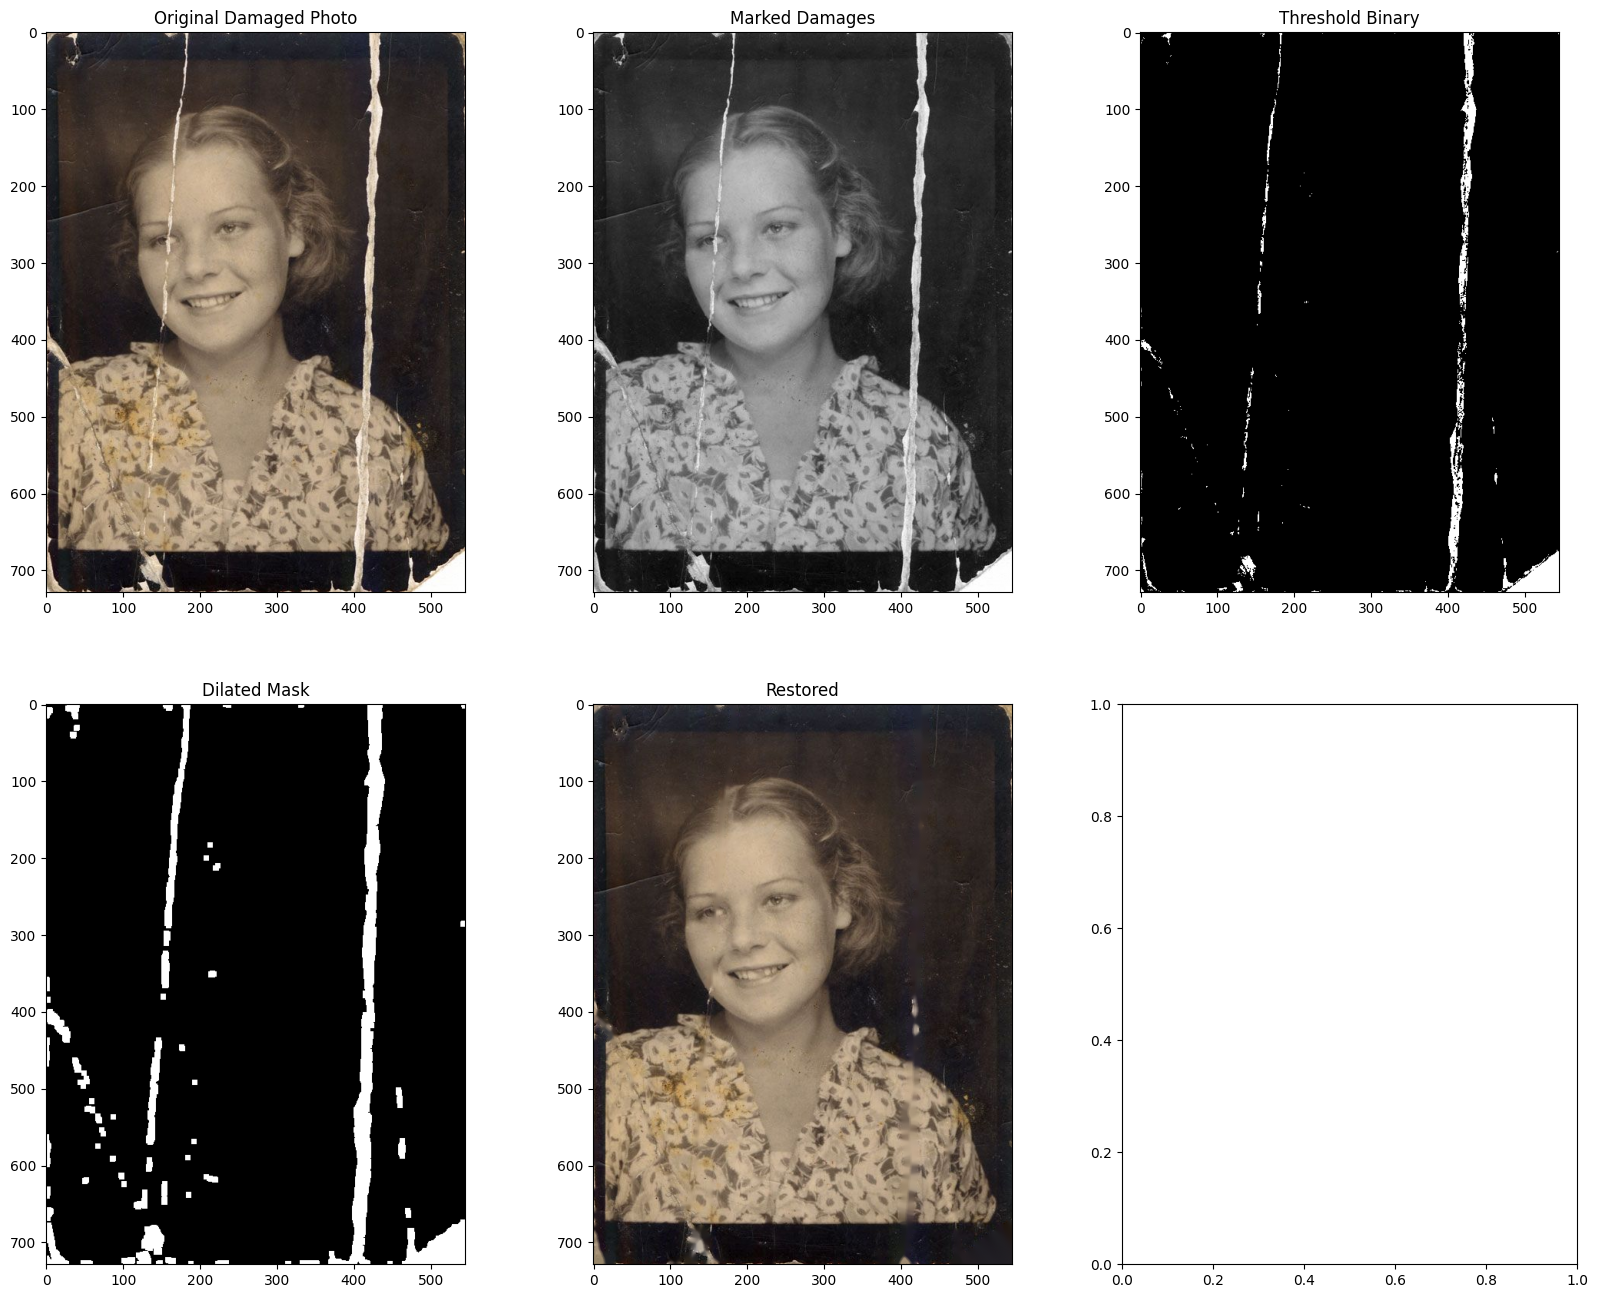

In [ ]:
# Load the original damaged image (in color)
img_path = 'damaged_02.jpg'
image = cv2.imread(img_path)   # Used as the input image to be restored

# Load the same image in grayscale to mark damaged areas
marked_damages = cv2.imread(img_path, 0)  # Used to create a damage mask

# Convert marked image into a binary image
# White = damaged area, Black = normal area
# 195 → Threshold value:
#      Pixels with intensity > 195 are treated as damaged (white),
#      pixels ≤ 195 are treated as normal (black)

# 255 → Maximum value:
#      Pixels classified as damaged are set to pure white (255)
ret, thresh1 = cv2.threshold(
    marked_damages, 195, 255, cv2.THRESH_BINARY
)  # Separates damaged areas (white) from background (black)

# Create a kernel (small matrix) for dilation
kernel = np.ones((7,7), np.uint8)   # Used to control thickness of mask

# Dilate the binary image to make damaged areas thicker
mask = cv2.dilate(
    thresh1, kernel, iterations=1
)  # Used so inpainting covers full damaged regions


# 4 → Inpainting radius:
#     Defines how far (in pixels) OpenCV looks around the damaged area
#     to collect surrounding information for filling
restored = cv2.inpaint(
    image, mask, 4, cv2.INPAINT_TELEA
)  # Restores damaged regions using nearby pixels


cv2.imwrite('Original Damaged Photo.png',image)
cv2.imwrite('Restored.png',restored)


# Convert original image from BGR to RGB for correct display
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Used for proper matplotlib colors

# Convert restored image from BGR to RGB for correct display
restored = cv2.cvtColor(restored, cv2.COLOR_BGR2RGB)  # Used for proper display

# Create a grid of subplots for visualization
fig, ax = plt.subplots(2, 3, figsize=(20,16))  # Used to compare each step visually
ax = ax.ravel()                                # Flatten axes for easy indexing

# Display original damaged image
ax[0].imshow(image)
ax[0].set_title('Original Damaged Photo')

# Display grayscale marked damages
ax[1].imshow(marked_damages, cmap='gray')
ax[1].set_title('Marked Damages')

# Display thresholded binary image
ax[2].imshow(thresh1, cmap='gray')
ax[2].set_title('Threshold Binary')

# Display dilated mask
ax[3].imshow(mask, cmap='gray')
ax[3].set_title('Dilated Mask')

# Display restored image
ax[4].imshow(restored)
ax[4].set_title('Restored')
